# Time series of TRISHNA-like water products (datacube)

## Requirements
- A time series of GRS L2A Sentinel-2 products on one tile.

## Tutorial objectives
- Build a 60 m datacube of TRISHNA-like water products from a Sentinel-2 L2A time series.
- Compare the time series of products available with TRISHNA and with all S2 bands.
- Follow the optical water types through time.

## Environment
Use the `sandbox_env` kernel of the CNES JupyterHub. Otherwise install the packages below in your environment (the `trishna_tbx` toolbox: `pip install -e <path>/trishna_tbx`):

`GRSdriver`, `grs`, `GRSl2bgen`, `radcalnet_oc`, `invRrs`, `trishna_tbx`, `matplotlib`, `pandas`, `xarray`.

## Resources
The code can be executed with the CPU: 2 cores, 8 GB. Run time: ~5 min.

![version](https://img.shields.io/badge/version-11.2026-blue)

## Imports

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

import trishna_tbx
from trishna_tbx import TRISHNA, make_s2
print('trishna_tbx', trishna_tbx.__version__)
from pathlib import Path
THUMB_DIR = Path('../thumbnails').resolve() if Path('../thumbnails').exists() else Path('.').resolve()
# plot style: Times-like serif fonts with LaTeX-style math (STIX, no TeX installation needed),
# larger fonts, minor ticks on all axes
plt.rcParams.update({'figure.dpi': 90, 'font.size': 14, 'font.family': 'STIXGeneral',
                     'mathtext.fontset': 'stix', 'axes.titlesize': 15, 'axes.labelsize': 15,
                     'legend.fontsize': 12, 'xtick.labelsize': 13, 'ytick.labelsize': 13,
                     'xtick.minor.visible': True, 'ytick.minor.visible': True})

from trishna_tbx import algorithms, owt
from trishna_tbx.io import list_l2a, open_grs_l2a, water_mask, to_60m
from trishna_tbx.emulate import owt_band_adjustment

trishna_tbx 0.0.1


## Data
> **Data paths.** On the CNES JupyterHub, point the variables below to the TREX datalake or to your project space. Outside CNES, download Sentinel-2 L1C with the *Access data - Copernicus API* tutorial. Each path can also be set through the environment variable named in the cell.

In [2]:
import os
from pathlib import Path

# ---- edit here (or set the environment variables) ------------------------------------
S2_L1C = os.environ.get('TRISHNA_TBX_S2_L1C',
    '/data/satellite/Sentinel-2/L1C/31TFJ/2025/05/26/'
    'S2B_MSIL1C_20250526T103629_N0511_R008_T31TFJ_20250526T123708.SAFE')
CAMS_FILE = os.environ.get('TRISHNA_TBX_CAMS', '/data/cams/world/cams_forecast_2025-05.nc')
# 30 km box (UTM 31N) over the Berre lagoon and the eastern Gulf of Fos
SUBSET = [(655000, 4800000, 685000, 4830000)]
L2A_DIR = os.environ.get('TRISHNA_TBX_L2A_DIR',
    '/home/harmel/Dropbox/Dropbox/work/projet/unesco/satellite/L2A')  # GRS L2A (beam profile)
L2A_TILE = 'T33PVQ'                      # Lake Chad (southern pool)
L2A_WINDOW = 'y=0:3600,x=0:960'          # 20 m pixel window with water
L2A_DATE = '2022-02-12'                  # date used by the single-image tutorials
# single-image example of the products tutorial: Loire estuary and plume, GRS v3.1.1 (Zarr pyramid,
# local S3 bucket grstbx-s3 of grstbx, read here through its folder)
L2A_EXAMPLE = os.environ.get('TRISHNA_TBX_L2A_EXAMPLE',
    '/data/satellite/s3/grstbx-s3/sentinel-2/l2a/30TWT/2017/04/12/'
    'S2A_MSIL2AGRS_20170412T110621_N0500_R137_T30TWT_20231111T110836_V3.1.1/'
    'S2A_MSIL2AGRS_20170412T110621_N0500_R137_T30TWT_20231111T110836_V3.1.1.zarr')
L2A_EXAMPLE_WINDOW = 'y=2700:5490,x=1500:4500'   # 20 m pixels: estuary, plume, Bourgneuf Bay
L2B_EXAMPLE = os.environ.get('TRISHNA_TBX_L2B_EXAMPLE',   # GRSl2bgen L2B of the same image
    '/data/satellite/s3/grstbx-s3/sentinel-2/l2b/30TWT/2017/04/12/'
    'S2A_MSIL2B_20170412T110621_N0500_R137_T30TWT_20231111T110836_V3.1.1/'
    'S2A_MSIL2B_20170412T110621_N0500_R137_T30TWT_20231111T110836_V3.1.1.zarr')
AERONET_HYP_DIR = os.environ.get('TRISHNA_TBX_AERONET_HYP', '/DATA/AERONET/OCv3_invRrs/data')
OUTPUT_DIR = Path(os.environ.get('TRISHNA_TBX_OUTPUT', './output')).resolve()
# ---------------------------------------------------------------------------------------
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Build the datacube
For each date: water pixels, 60 m averaging, then products from all S2 bands and from
TRISHNA-like Rrs (S2 490/560/665/865 nm with OWT-dependent S2 -> TRISHNA band adjustment and
requirement noise), and OWT with both band sets.

In [3]:
files = list_l2a(L2A_DIR, L2A_TILE)
print(len(files), 'dates:', str(files[0][0])[:10], '->', str(files[-1][0])[:10])
s2 = make_s2()
S2W = s2.subset(['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8A'], 'S2')
S2T = s2.subset(['B2', 'B3', 'B4', 'B8A'], 'S2-as-TRISHNA')
ref, _ = owt.load_reference('Bi2024')
sig = TRISHNA.subset(['Blue', 'Green', 'Red', 'NIR']).noise_reflectance(30.) / (np.pi * 0.75)
rng = np.random.default_rng(0)

def classify(rrs_, sens):
    r = owt.convolve_reference(ref, sens)
    x = rrs_.sel(wl=r.wl.values, method='nearest').rename(wl='band').assign_coords(band=r.band.values)
    v = x.notnull().all('band')
    c, _ = owt.classify(x.where(v), r.drop_vars('wl'), dim='band')
    return owt.merge_classes(c.where(v))

cubes = []
for t, f in files:
    ds = open_grs_l2a(f, L2A_WINDOW)
    rrs = to_60m(ds.Rrs.where(water_mask(ds))).load()
    rrs = rrs.where((rrs.sel(wl=[490, 560, 665]) > 0).all('wl'))
    rt, _, _ = owt_band_adjustment(rrs.sel(wl=[490, 560, 665, 865]), S2T)
    rt = rt + xr.DataArray(sig.values, dims='wl', coords={'wl': rt.wl}) * xr.DataArray(
        rng.standard_normal(rt.shape), dims=rt.dims)
    pt = algorithms.run_all(rt, S2T)
    ps = algorithms.run_all(rrs, s2)
    cube = xr.Dataset({
        'SPM_trishna': pt.SPM_Nechad10, 'TUR_trishna': pt.TUR_Dogliotti15, 'Kd490_trishna': pt.Kd490_KD2,
        'SPM_s2': ps.SPM_Nechad10, 'TUR_s2': ps.TUR_Dogliotti15, 'Kd490_s2': ps.Kd490_KD2,
        'NDCI_s2': ps.Chla_index_NDCI,
        'owt_trishna': classify(rrs, S2T).astype(str), 'owt_s2': classify(rrs, S2W).astype(str)})
    cubes.append(cube.expand_dims(time=[t]))
cube = xr.concat(cubes, 'time')
cube

20 dates: 2022-01-01 -> 2022-02-27


<xarray.Dataset> Size: 614MB
Dimensions:        (time: 20, y: 1200, x: 320)
Coordinates:
  * time           (time) datetime64[s] 160B 2022-01-01T09:33:09 ... 2022-02-...
  * y              (y) float64 10kB 1.5e+06 1.5e+06 ... 1.428e+06 1.428e+06
  * x              (x) float64 3kB 4e+05 4e+05 4.001e+05 ... 4.191e+05 4.191e+05
Data variables:
    SPM_trishna    (time, y, x) float64 61MB nan nan nan nan ... 5.636 nan nan
    TUR_trishna    (time, y, x) float64 61MB nan nan nan nan ... 3.63 nan nan
    Kd490_trishna  (time, y, x) float64 61MB nan nan nan nan ... 1.499 nan nan
    SPM_s2         (time, y, x) float64 61MB nan nan nan nan ... 4.68 nan nan
    TUR_s2         (time, y, x) float64 61MB nan nan nan nan ... 3.012 nan nan
    Kd490_s2       (time, y, x) float64 61MB nan nan nan nan ... 0.3833 nan nan
    NDCI_s2        (time, y, x) float64 61MB nan nan nan nan ... 0.4317 nan nan
    owt_trishna    (time, y, x) <U3 92MB 'nan' 'nan' 'nan' ... '5b' 'nan' 'nan'
    owt_s2         (time, y, x) <U3 92MB 'nan' 'nan' 'nan' ... '5b' 'nan' 'nan'

In [4]:
f = OUTPUT_DIR / f'datacube_trishna_{L2A_TILE}.nc'
cube.to_netcdf(f); print(f)

/home/harmel/Dropbox/Dropbox/work/git/satellite_app/trishna_tbx/notebooks/4_visualisation/output/datacube_trishna_T33PVQ.nc


## 2. Time series over the lake

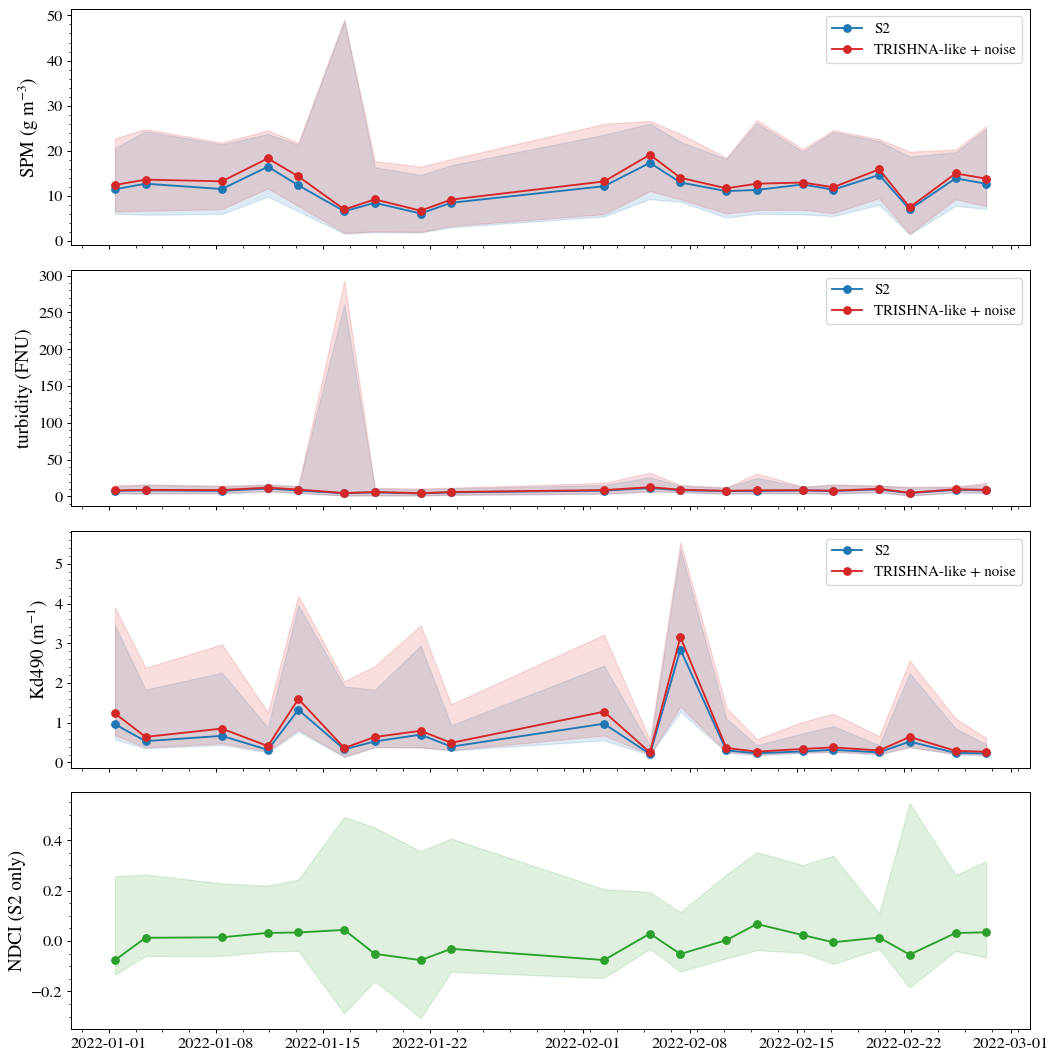

In [5]:
valid = cube.SPM_s2.notnull().sum(['x', 'y'])
keep = valid > 0.2 * valid.max()   # dates with enough water pixels (clouds)
c = cube.sel(time=keep)
fig, axs = plt.subplots(4, 1, figsize=(12, 12), sharex=True)
for ax, (v, lab) in zip(axs, [('SPM', 'SPM (g m$^{-3}$)'), ('TUR', 'turbidity (FNU)'), ('Kd490', 'Kd490 (m$^{-1}$)')]):
    for src, col in [('s2', 'tab:blue'), ('trishna', 'tab:red')]:
        q = c[f'{v}_{src}'].quantile([0.1, 0.5, 0.9], dim=['x', 'y'])
        ax.fill_between(c.time, q.sel(quantile=.1), q.sel(quantile=.9), color=col, alpha=.15)
        ax.plot(c.time, q.sel(quantile=.5), 'o-', c=col, label='S2' if src == 's2' else 'TRISHNA-like + noise')
    ax.set_ylabel(lab); ax.legend()
q = c.NDCI_s2.quantile([0.1, 0.5, 0.9], dim=['x', 'y'])
axs[3].fill_between(c.time, q.sel(quantile=.1), q.sel(quantile=.9), color='tab:green', alpha=.15)
axs[3].plot(c.time, q.sel(quantile=.5), 'o-', c='tab:green'); axs[3].set_ylabel('NDCI (S2 only)')
fig.tight_layout()
fig.savefig(THUMB_DIR / 'datacube_trishna.png', dpi=60)

## 3. Optical water types through time

Text(0, 0.5, 'fraction of water pixels')

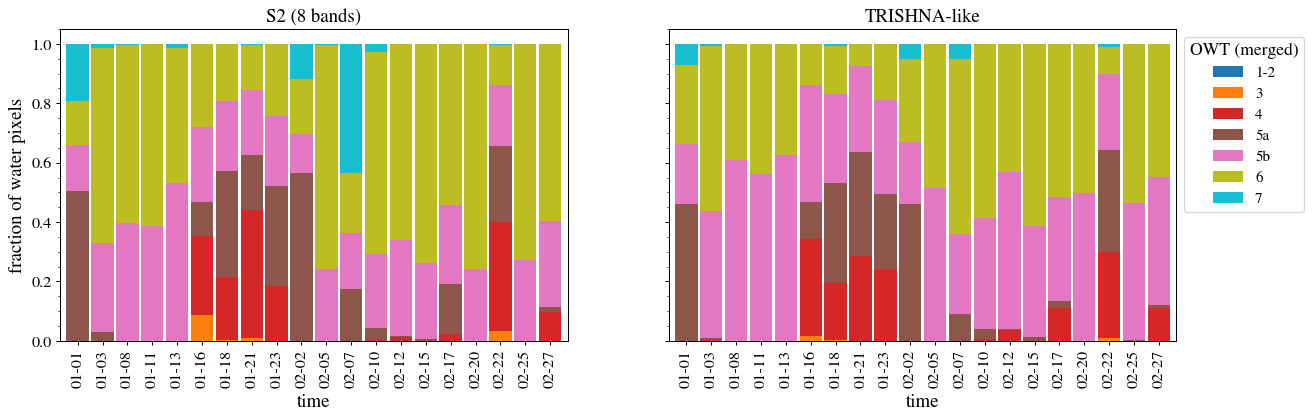

In [6]:
def occurrence(v):
    df = c[v].to_dataframe(name='owt').reset_index()
    df = df[df.owt.isin(sorted(set(owt.TRISHNA_MERGE.values())))]
    return pd.crosstab(df.time, df.owt, normalize='index')

fig, axs = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
for ax, (v, t) in zip(axs, [('owt_s2', 'S2 (8 bands)'), ('owt_trishna', 'TRISHNA-like')]):
    o = occurrence(v); o.index = o.index.strftime('%m-%d')
    o.plot.bar(stacked=True, ax=ax, width=.9, colormap='tab10', legend=ax is axs[1]); ax.set_title(t)
    ax.xaxis.set_minor_locator(plt.NullLocator())
axs[1].legend(bbox_to_anchor=(1, 1), title='OWT (merged)'); axs[0].set_ylabel('fraction of water pixels')

## 4. Maps
SPM from TRISHNA-like bands for a few dates.

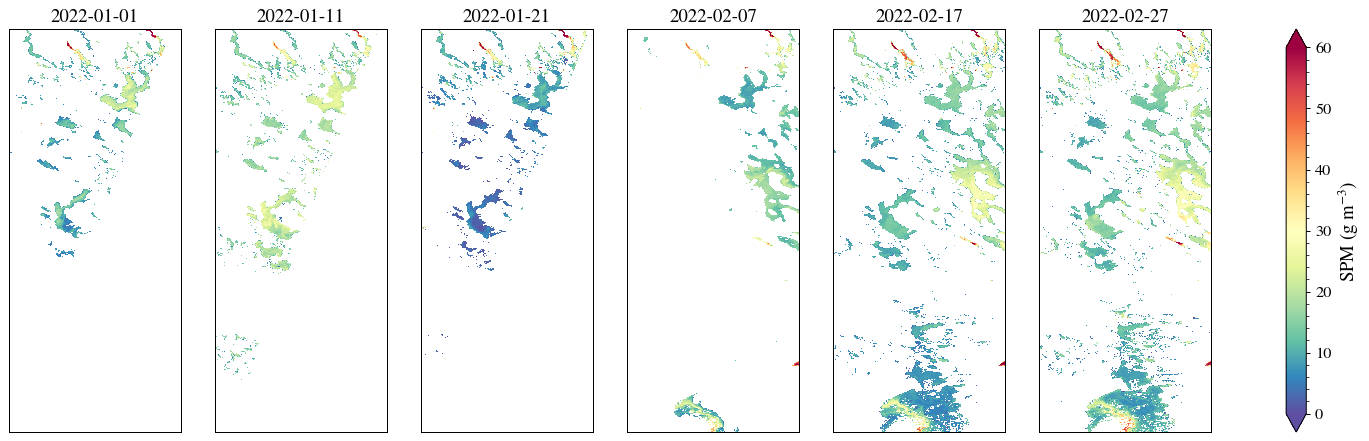

In [7]:
sel = c.isel(time=np.linspace(0, c.sizes['time'] - 1, 6).astype(int))
g = sel.SPM_trishna.plot(col='time', col_wrap=6, vmin=0, vmax=60, cmap='Spectral_r', figsize=(18, 6),
                         cbar_kwargs={'label': 'SPM (g m$^{-3}$)'})
for ax, t in zip(g.axs.ravel(), sel.time.values):
    ax.set_xticks([]); ax.set_yticks([]); ax.minorticks_off(); ax.set_xlabel(''); ax.set_ylabel('')
    ax.set_title(str(t)[:10])

## Take-home messages
- The temporal dynamics of SPM, turbidity and Kd490 are preserved with TRISHNA-like bands,
  but with a systematic offset due to the band differences (here SPM/turbidity +7 to +16 %,
  Kd490 +20 to +40 % with S2 coefficients): coefficients must be re-tuned for TRISHNA before
  merging S2 and TRISHNA time series.
- Phytoplankton dynamics seen by the red-edge index (NDCI) cannot be followed with TRISHNA.
- TRISHNA revisit (3 acquisitions every 8 days, day and night for the TIR) will densify these
  series, but with variable viewing angles (up to 38 deg): angular effects and sunglint have
  to be handled (GRS).